In [1]:
import numpy as np 
from tqdm import tqdm
import cv2
import os
import imutils
import matplotlib.pyplot as plt
import tensorflow as tf

#### Cropping the images to remove background

In [2]:
def crop_img(img):
	"""
	Finds the extreme points on the image and crops the rectangular out of them
	"""
	gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
	gray = cv2.GaussianBlur(gray, (3, 3), 0)

	# threshold the image, then perform a series of erosions +
	# dilations to remove any small regions of noise
	thresh = cv2.threshold(gray, 45, 255, cv2.THRESH_BINARY)[1]
	thresh = cv2.erode(thresh, None, iterations=2)
	thresh = cv2.dilate(thresh, None, iterations=2)

	# find contours in thresholded image, then grab the largest one
	cnts = cv2.findContours(thresh.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
	cnts = imutils.grab_contours(cnts)
	c = max(cnts, key=cv2.contourArea)

	# find the extreme points
	extLeft = tuple(c[c[:, :, 0].argmin()][0])
	extRight = tuple(c[c[:, :, 0].argmax()][0])
	extTop = tuple(c[c[:, :, 1].argmin()][0])
	extBot = tuple(c[c[:, :, 1].argmax()][0])
	ADD_PIXELS = 0
	new_img = img[extTop[1]-ADD_PIXELS:extBot[1]+ADD_PIXELS, extLeft[0]-ADD_PIXELS:extRight[0]+ADD_PIXELS].copy()
	
	return new_img

#### Creating a cropped folder in which cropped training and testing images are stored

In [4]:
if __name__ == "__main__":
	# Use correct paths matching workspace structure
	training = "data/Training"
	testing = "data/Testing"
	training_dir = os.listdir(training)
	testing_dir = os.listdir(testing)
	IMG_SIZE = 200
	
	# Process training images with error handling and progress tracking
	for category in tqdm(training_dir, desc="Processing training images"):
		save_path = os.path.join('data', 'cropped', 'Training', category)
		path = os.path.join(training, category)
		
		# Create output directory
		os.makedirs(save_path, exist_ok=True)
		
		image_dir = os.listdir(path)
		for img_name in image_dir:
			try:
				img_path = os.path.join(path, img_name)
				image = cv2.imread(img_path)
				
				# Validate image was loaded
				if image is None:
					print(f"Warning: Could not read {img_path}, skipping...")
					continue
				
				new_img = crop_img(image)
				new_img = cv2.resize(new_img, (IMG_SIZE, IMG_SIZE))
				
				# Save with proper path joining
				save_file_path = os.path.join(save_path, img_name)
				cv2.imwrite(save_file_path, new_img)
			except Exception as e:
				print(f"Error processing {img_name}: {e}")
				continue
	
	# Process testing images with error handling and progress tracking
	for category in tqdm(testing_dir, desc="Processing testing images"):
		save_path = os.path.join('data', 'cropped', 'Testing', category)
		path = os.path.join(testing, category)
		
		# Create output directory
		os.makedirs(save_path, exist_ok=True)
		
		image_dir = os.listdir(path)
		for img_name in image_dir:
			try:
				img_path = os.path.join(path, img_name)
				image = cv2.imread(img_path)
				
				# Validate image was loaded
				if image is None:
					print(f"Warning: Could not read {img_path}, skipping...")
					continue
				
				new_img = crop_img(image)
				new_img = cv2.resize(new_img, (IMG_SIZE, IMG_SIZE))
				
				# Save with proper path joining
				save_file_path = os.path.join(save_path, img_name)
				cv2.imwrite(save_file_path, new_img)
			except Exception as e:
				print(f"Error processing {img_name}: {e}")
				continue
	
	print("Image cropping and resizing completed successfully!")

Processing testing images: 100%|██████████| 4/4 [00:02<00:00,  1.73it/s]

Image cropping and resizing completed successfully!


In [5]:
training_dir

['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']

#### Cropped images Demo 

In [8]:
# Load a sample cropped image for demonstration
import os

# Find first available image from cropped data
sample_img_path = None
for category in os.listdir('data/cropped/Training'):
    cat_path = os.path.join('data/cropped/Training', category)
    if os.path.isdir(cat_path):
        images = [f for f in os.listdir(cat_path) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
        if images:
            sample_img_path = os.path.join(cat_path, images[0])
            print(f"✓ Loading sample image: {sample_img_path}")
            break

if sample_img_path is None:
    print("✗ Error: No images found in data/cropped/Training/")
else:
    img = cv2.imread(sample_img_path)
    if img is None:
        print(f"✗ Error: Could not read image: {sample_img_path}")
    else:
        img = cv2.resize(img, dsize=(224,224), interpolation=cv2.INTER_CUBIC)
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        gray = cv2.GaussianBlur(gray, (5, 5), 0)

        # threshold the image, then perform a series of erosions + dilations to remove noise
        thresh = cv2.threshold(gray, 45, 255, cv2.THRESH_BINARY)[1]
        thresh = cv2.erode(thresh, None, iterations=2)
        thresh = cv2.dilate(thresh, None, iterations=2)

        # find contours in thresholded image, then grab the largest one
        cnts = cv2.findContours(thresh.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cnts = imutils.grab_contours(cnts)
        c = max(cnts, key=cv2.contourArea)

        # find the extreme points
        extLeft = tuple(c[c[:, :, 0].argmin()][0])
        extRight = tuple(c[c[:, :, 0].argmax()][0])
        extTop = tuple(c[c[:, :, 1].argmin()][0])
        extBot = tuple(c[c[:, :, 1].argmax()][0])

        # add contour on the image
        img_cnt = cv2.drawContours(img.copy(), [c], -1, (0, 255, 255), 4)

        # add extreme points
        img_pnt = cv2.circle(img_cnt.copy(), extLeft, 8, (0, 0, 255), -1)
        img_pnt = cv2.circle(img_pnt, extRight, 8, (0, 255, 0), -1)
        img_pnt = cv2.circle(img_pnt, extTop, 8, (255, 0, 0), -1)
        img_pnt = cv2.circle(img_pnt, extBot, 8, (255, 255, 0), -1)

        # crop
        ADD_PIXELS = 0
        new_img = img[extTop[1]-ADD_PIXELS:extBot[1]+ADD_PIXELS, extLeft[0]-ADD_PIXELS:extRight[0]+ADD_PIXELS].copy()

✓ Loading sample image: data/cropped/Training\glioma_tumor\gg (1).jpg


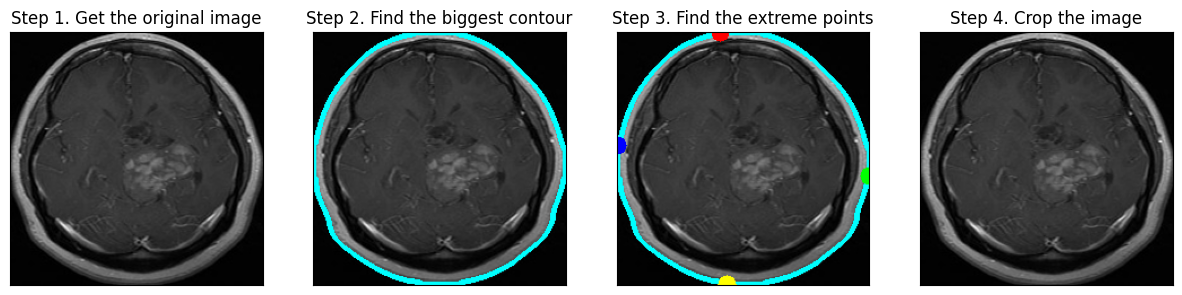

In [9]:
plt.figure(figsize=(15,6))
plt.subplot(141)
plt.imshow(img)
plt.xticks([])
plt.yticks([])
plt.title('Step 1. Get the original image')
plt.subplot(142)
plt.imshow(img_cnt)
plt.xticks([])
plt.yticks([])
plt.title('Step 2. Find the biggest contour')
plt.subplot(143)
plt.imshow(img_pnt)
plt.xticks([])
plt.yticks([])
plt.title('Step 3. Find the extreme points')
plt.subplot(144)
plt.imshow(new_img)
plt.xticks([])
plt.yticks([])
plt.title('Step 4. Crop the image')
plt.show()

In [10]:
X_train = []
y_train = []
X_test = []
y_test = []
image_size = 200
labels = ['glioma_tumor','meningioma_tumor','no_tumor','pituitary_tumor']

# Load training images
for label in tqdm(labels, desc="Loading training data"):
    folderpath = os.path.join('data', 'cropped', 'Training', label)
    if not os.path.exists(folderpath):
        print(f"Warning: Training folder not found: {folderpath}")
        continue
    
    for img_name in os.listdir(folderpath):
        try:
            img_path = os.path.join(folderpath, img_name)
            image = cv2.imread(img_path, 0)  # Load in grayscale
            
            if image is None:
                continue
            
            image = cv2.bilateralFilter(image, 2, 50, 50)  # Remove noise
            image = cv2.applyColorMap(image, cv2.COLORMAP_BONE)  # Pseudocolor
            image = cv2.resize(image, (image_size, image_size))  # Resize
            
            X_train.append(image)
            y_train.append(labels.index(label))
        except Exception as e:
            print(f"Error loading {img_name}: {e}")
            continue

# Load testing images
for label in tqdm(labels, desc="Loading testing data"):
    folderpath = os.path.join('data', 'cropped', 'Testing', label)
    if not os.path.exists(folderpath):
        print(f"Warning: Testing folder not found: {folderpath}")
        continue
    
    for img_name in os.listdir(folderpath):
        try:
            img_path = os.path.join(folderpath, img_name)
            image = cv2.imread(img_path, 0)  # Load in grayscale
            
            if image is None:
                continue
            
            image = cv2.bilateralFilter(image, 2, 50, 50)  # Remove noise
            image = cv2.applyColorMap(image, cv2.COLORMAP_BONE)  # Pseudocolor
            image = cv2.resize(image, (image_size, image_size))  # Resize
            
            X_test.append(image)
            y_test.append(labels.index(label))
        except Exception as e:
            print(f"Error loading {img_name}: {e}")
            continue

# Normalize images to 0-1 range
X_train = np.array(X_train) / 255.0
X_test = np.array(X_test) / 255.0

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Loading testing data: 100%|██████████| 4/4 [00:00<00:00, 10.68it/s]


Training set shape: (2870, 200, 200, 3)
Testing set shape: (394, 200, 200, 3)


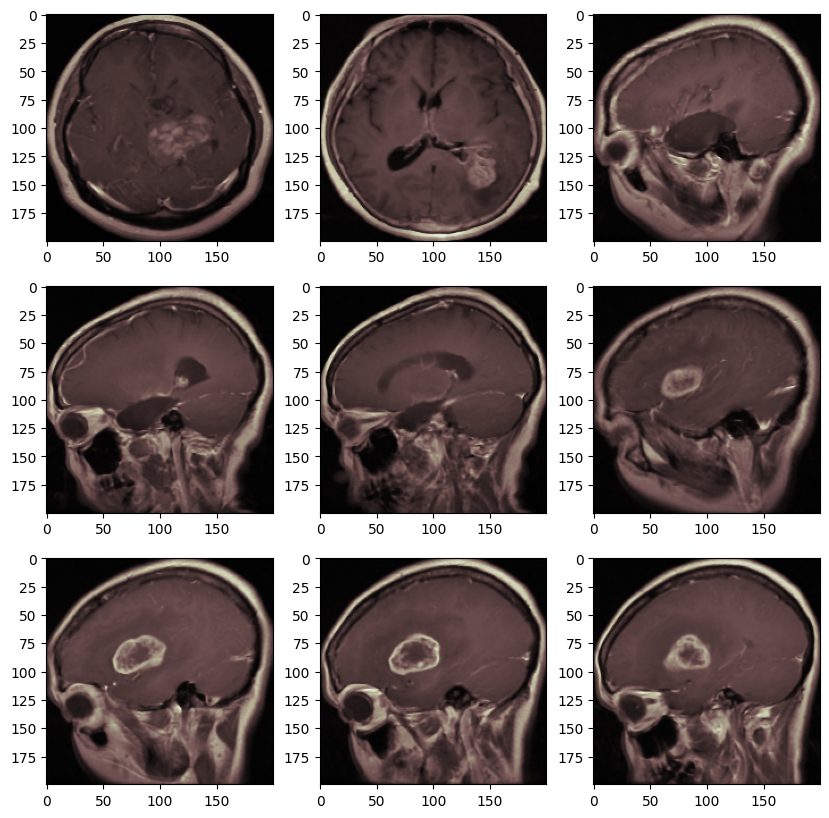

In [11]:
images = [X_train[i] for i in range(9)]
fig, axes = plt.subplots(3, 3, figsize = (10, 10))
axes = axes.flatten()
for img, ax in zip(images, axes):
    ax.imshow(img)
#plt.tight_layout()
plt.show()

In [12]:
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split

In [13]:
X_train, y_train = shuffle(X_train,y_train, random_state=42) 

In [14]:
y_train = tf.keras.utils.to_categorical(y_train) #One Hot Encoding on the labels
y_test = tf.keras.utils.to_categorical(y_test)

In [15]:
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42) #Dividing the dataset into Training and Validation sets.
print(X_val.shape)
print(X_train.shape)
print(X_test.shape)

(574, 200, 200, 3)
(2296, 200, 200, 3)
(394, 200, 200, 3)


#### Image Augmentation

In [16]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D,MaxPool2D,Flatten,Dense,Dropout,GlobalAveragePooling2D
from tensorflow.keras.models import Sequential,Model
from tensorflow.keras.optimizers import Adam

In [17]:
# ImageDataGenerator transforms each image in the batch by a series of random translations, rotations, etc.
datagen = ImageDataGenerator(
     rotation_range=10,                        
    width_shift_range=0.05,
    height_shift_range=0.05,
    horizontal_flip=True)

# After you have created and configured your ImageDataGenerator, you must fit it on your data.
datagen.fit(X_train)

#### Model Training

In [18]:
from tensorflow.keras.applications.resnet import ResNet50
IMG_SIZE=(200,200)
base_model = ResNet50(
    include_top=False,
    input_shape=IMG_SIZE + (3,),
    weights='imagenet')

# Unfreeze more layers for better fine-tuning (train top 100 layers)
for layer in base_model.layers[:-100]:
    layer.trainable = False
for layer in base_model.layers[-100:]:
    layer.trainable = True

In [19]:
base_model.summary()

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 200, 200,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 206, 206,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 100, 100,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 100, 100,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 100, 100,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 102, 102,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 50, 50,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 50, 50,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 50, 50,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 50, 50,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 50, 50,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 50, 50,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 50, 50,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 50, 50,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 50, 50,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 50, 50,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 50, 50,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 22,151,936 (84.50 MB)

 Non-trainable params: 1,435,776 (5.48 MB)

In [20]:
# Customized layers with optimized dropout
x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.4)(x)
predict = Dense(4, activation='softmax')(x)

# Create a model object
model = Model(inputs=base_model.input, outputs=predict)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 200, 200,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 206, 206,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 100, 100,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 100, 100,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 100, 100,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 102, 102,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 50, 50,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 50, 50,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 50, 50,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 50, 50,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 50, 50,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 50, 50,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 50, 50,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 50, 50,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 50, 50,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 50, 50,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 50, 50,    │      1,024 │ conv2_block1_3_c

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 22,160,132 (84.53 MB)

 Non-trainable params: 1,435,776 (5.48 MB)

In [21]:
#compile our model with optimized learning rate
adam = Adam(learning_rate=0.0005)
model.compile(optimizer=adam, loss='categorical_crossentropy', metrics=['accuracy'])

In [22]:
train_len = len(X_train)
val_len = len(X_val)
print("-----------Training Data length-----------------")
print(train_len)

print("-----------Validation Data length-----------------")
print(val_len)

-----------Training Data length-----------------
2296
-----------Validation Data length-----------------
574


In [23]:
# Add callbacks for better training control
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=0.00001, verbose=1)

hist = model.fit(datagen.flow(X_train, y_train, batch_size=32),
                validation_data=(X_val, y_val),
                epochs=30,
                callbacks=[early_stop, reduce_lr],
                verbose=1)

Epoch 1/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 250s 3s/step - accuracy: 0.4268 - loss: 1.3011 - val_accuracy: 0.3240 - val_loss: 5.1641 - learning_rate: 5.0000e-04
Epoch 2/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 321s 4s/step - accuracy: 0.5523 - loss: 1.0301 - val_accuracy: 0.3850 - val_loss: 5.7375 - learning_rate: 5.0000e-04
Epoch 3/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 263s 4s/step - accuracy: 0.6381 - loss: 0.8876 - val_accuracy: 0.4808 - val_loss: 4.0626 - learning_rate: 5.0000e-04
Epoch 4/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 226s 3s/step - accuracy: 0.6943 - loss: 0.7493 - val_accuracy: 0.6585 - val_loss: 1.2237 - learning_rate: 5.0000e-04
Epoch 5/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 226s 3s/step - accuracy: 0.7474 - loss: 0.6370 - val_accuracy: 0.4721 - val_loss: 2.1010 - learning_rate: 5.0000e-04
Epoch 6/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 225s 3s/step - accuracy: 0.7831 - loss: 0.5507 - val_accuracy: 0.4530 - val_loss: 2.4684 - learning_rate: 5.0000e-04
Epoch 7/30
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7890 - 

#### Plotting output results

In [24]:
#Plotting the results
acc = hist.history['accuracy']
val_acc = hist.history['val_accuracy']
loss = hist.history['loss']
val_loss = hist.history['val_loss']

Text(0.5, 1.0, 'Training and Validation Loss')

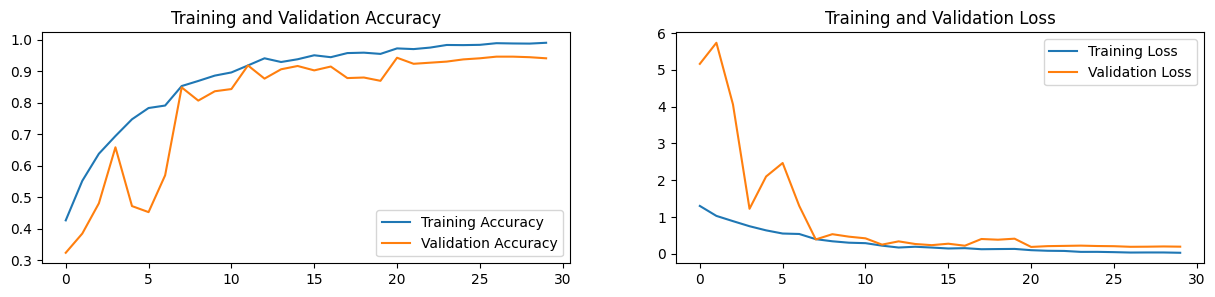

In [25]:
plt.figure(figsize=(15,3))
plt.subplot(1,2,1)
plt.plot(acc,label='Training Accuracy')
plt.plot(val_acc,label='Validation Accuracy')
plt.legend(loc= "lower right")
plt.title("Training and Validation Accuracy")

plt.subplot(1,2,2)
plt.plot(loss,label='Training Loss')
plt.plot(val_loss,label='Validation Loss')
plt.legend(loc= "upper right")
plt.title("Training and Validation Loss")

In [26]:
#Saving the model
from keras.models import load_model
model.save('bestresnet.h5')

#### Validation on Test set

In [27]:
loss,acc = model.evaluate(X_test,y_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 947ms/step - accuracy: 0.7487 - loss: 1.8651


#### Classification Report

In [28]:
from sklearn.metrics import classification_report,accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
predicted_classes = np.argmax(model.predict(X_test), axis = 1)
print(classification_report(np.argmax(y_test,axis=1), predicted_classes,target_names=['glioma','meningioma','no_tumor','pituitary']))

13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step 
              precision    recall  f1-score   support

      glioma       0.90      0.28      0.43       100
  meningioma       0.67      0.97      0.79       115
    no_tumor       0.72      0.99      0.83       105
   pituitary       0.98      0.70      0.82        74

    accuracy                           0.75       394
   macro avg       0.82      0.73      0.72       394
weighted avg       0.80      0.75      0.72       394



#### Confusion Matrix

50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 298ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 14s 287ms/step


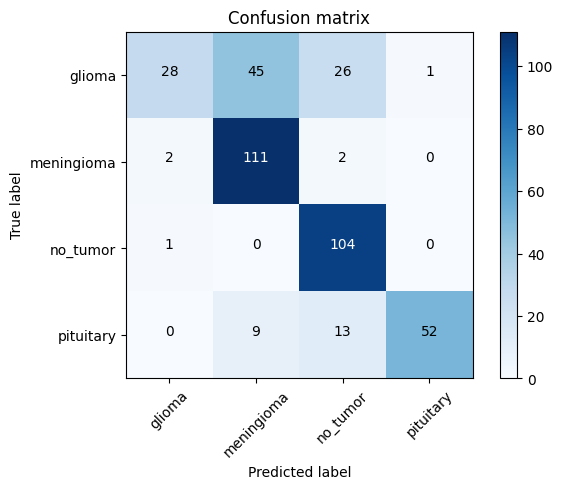

In [29]:
import itertools
pred_Y = model.predict(X_test, batch_size = 8, verbose = True)

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    target_names=['glioma','meningioma','no_tumor','pituitary']

    if target_names is not None:
        tick_marks = np.arange(len(target_names))
        plt.xticks(tick_marks, target_names, rotation=45)
        plt.yticks(tick_marks, target_names)
    
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

# Predict the values from the validation dataset
Y_pred = model.predict(X_test, batch_size=8)
# Convert predictions classes to one hot vectors 
Y_pred_classes = np.argmax(pred_Y,axis = 1) 
# Convert validation observations to one hot vectors
# compute the confusion matrix
rounded_labels=np.argmax(y_test, axis=1)
confusion_mtx = confusion_matrix(rounded_labels, Y_pred_classes)

 

# plot the confusion matrix
plot_confusion_matrix(confusion_mtx, classes = range(4)) 

#### Plotting sample predictions

13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 879ms/step


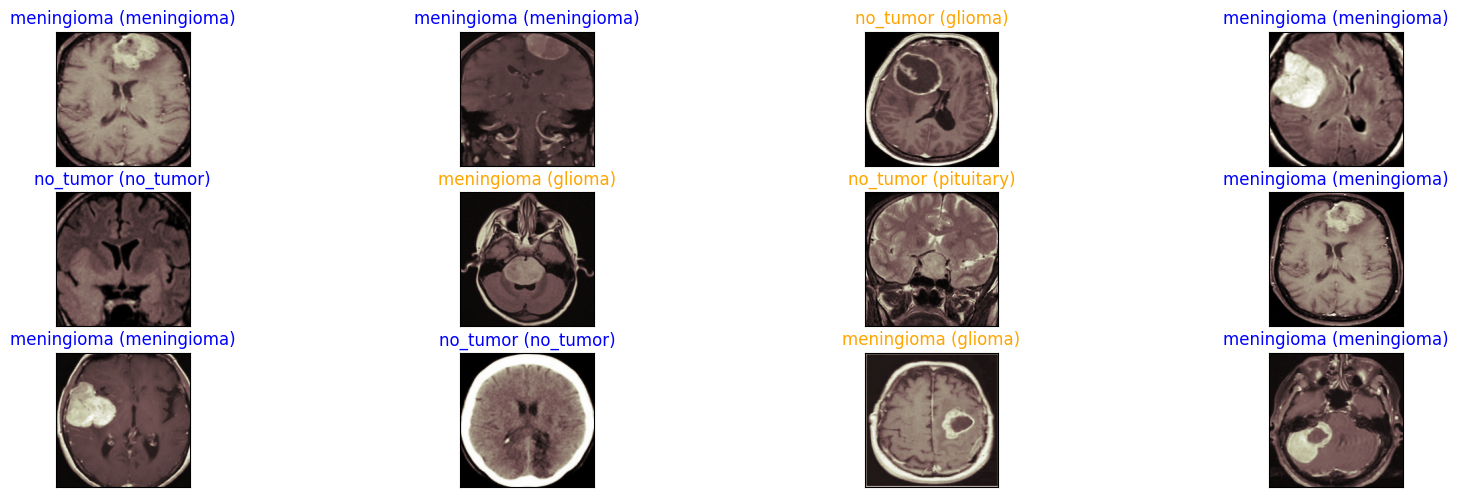

In [30]:
y_hat = model.predict(X_test)

# define text labels 
target_labels = ['glioma','meningioma','no_tumor','pituitary']

# plot a random sample of test images, their predicted labels, and ground truth
fig = plt.figure(figsize=(20, 8))
for i, idx in enumerate(np.random.choice(X_test.shape[0], size=12, replace=False)):
    ax = fig.add_subplot(4,4, i+1, xticks=[], yticks=[])
    ax.imshow(np.squeeze(X_test[idx]))
    pred_idx = np.argmax(y_hat[idx])
    true_idx = np.argmax(y_test[idx])
    ax.set_title("{} ({})".format(target_labels[pred_idx], target_labels[true_idx]),
                 color=("blue" if pred_idx == true_idx else "orange"))

In [32]:
from tensorflow.keras.models import load_model
model = load_model('bestresnet.h5')

In [34]:
#Predicting a particular image without image preprocessing
from tensorflow.keras.preprocessing import image
import os

labels = ['glioma_tumor','meningioma_tumor','no_tumor','pituitary_tumor']

# Find first available test image
sample_test_path = None
for category in labels:
    cat_path = os.path.join('data', 'cropped', 'Testing', category)
    if os.path.exists(cat_path):
        images = [f for f in os.listdir(cat_path) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
        if images:
            sample_test_path = os.path.join(cat_path, images[0])
            print(f"✓ Predicting image: {sample_test_path}")
            break

if sample_test_path is None:
    print("✗ Error: No test images found in data/cropped/Testing/")
else:
    try:
        img = image.load_img(sample_test_path, target_size=(200, 200))
        x = image.img_to_array(img)
        x = x / 255
        x = np.expand_dims(x, axis=0)
        
        predict_result = model.predict(x)
        predicted_idx = np.argmax(predict_result, axis=1)[0]
        confidence = predict_result[0][predicted_idx]
        
        print(f"\n{'='*50}")
        print(f"Predicted Class: {labels[predicted_idx]}")
        print(f"Confidence: {confidence:.4f} ({confidence*100:.2f}%)")
        print(f"{'='*50}")
        
        # Show all predictions
        print("\nAll class probabilities:")
        for i, label in enumerate(labels):
            print(f"  {label}: {predict_result[0][i]:.4f}")
    except Exception as e:
        print(f"✗ Error during prediction: {e}")

✓ Predicting image: data\cropped\Testing\glioma_tumor\image(1).jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step

Predicted Class: no_tumor
Confidence: 0.5506 (55.06%)

All class probabilities:
  glioma_tumor: 0.4287
  meningioma_tumor: 0.0207
  no_tumor: 0.5506
  pituitary_tumor: 0.0000
